# Predicción vs realidad — consumo de la capa oro

Este notebook **solo lee la capa oro** (`data/gold/pred_vs_real/`). No carga silver, no reentrena y no necesita el modelo: todo lo que muestra sale de cuatro tablas pequeñas.

| Tabla | Qué contiene | Se usa para |
|---|---|---|
| `group_metrics` | Por dimensión y grupo (aerolínea, aeropuerto, franja, temporada, mes, día, hora): vuelos, tasa real, probabilidad media, ROC-AUC, PR-AUC y matriz de confusión al umbral | KPIs, comparación por subgrupo, matrices de confusión, mayores brechas |
| `score_bins` | 100 bins de igual tamaño por probabilidad predicha, con vuelos y retrasados | Calibración, separación entre clases, ROC, PR, ganancia y costo |
| `timeseries` | Por día: vuelos, retrasados, suma de probabilidades | Evolución en el tiempo |
| `heat_hora_dia` | Por hora × día de la semana | Mapas de calor |

**Cómo leer las gráficas**

- **Real** = proporción de vuelos que de verdad salieron con ≥ 15 min de retraso. **Predicha** = promedio de la probabilidad del modelo. Si el modelo está bien calibrado, las dos coinciden **en promedio** dentro de cada grupo.
- Que coincidan en promedio no significa que acierte vuelo por vuelo: eso lo muestran ROC-AUC, PR-AUC y la matriz de confusión.
- Las curvas ROC, PR y de ganancia se reconstruyen desde 100 bins, así que son aproximaciones finas (resolución del 1 %), no las curvas exactas vuelo a vuelo.
- Los conteos son los de la **muestra** guardada en cada conjunto (ver `meta.json`), no los de toda la población.

## 0. Configuración y carga

In [1]:
import json
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

GOLD_DIR = Path("../data/gold/pred_vs_real")
FIG_DIR  = Path("../outputs/outputs_gold/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SET = "prueba"          # conjunto para los gráficos detallados; los demás (p. ej. "prospectivo") se muestran en KPIs y series
MIN_FLIGHTS = 2000      # grupos con menos vuelos en la muestra no se grafican
TOP_AIRPORTS = 20

COL_REAL, COL_PRED = "#1f4e79", "#e07b00"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "figure.dpi": 110, "axes.titlesize": 11})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

con = duckdb.connect()
T = {n: con.sql(f"SELECT * FROM read_parquet('{(GOLD_DIR / f'{n}.parquet').as_posix()}')").df()
     for n in ["group_metrics", "score_bins", "timeseries", "heat_hora_dia"]}
meta = json.loads((GOLD_DIR / "meta.json").read_text())
CONJ = sorted(T["group_metrics"].conjunto.unique(), key=lambda c: (c != "prueba", c))
assert SET in CONJ, f"El conjunto '{SET}' no existe en la capa oro. Disponibles: {CONJ}"

print(f"Modelo: {meta['modelo']} | horizonte de predicción: {meta['horizonte_min']} min | "
      f"costo falsa alarma : retraso perdido = {meta['costo_fp']} : {meta['costo_fn']}")
for c, m in meta["conjuntos"].items():
    print(f"  · {c}: {m['desde']} → {m['hasta']} | {m['vuelos_muestra']:,} vuelos en la muestra de {m['vuelos_poblacion']:,} | umbral {m['umbral']:.3f}")

Modelo: LightGBM | horizonte de predicción: 240 min | costo falsa alarma : retraso perdido = 1 : 3
  · prueba: 2025-09-01 → 2026-08-31 | 1,000,000 vuelos en la muestra de 6,921,534 | umbral 0.252


## 1. Resumen: ¿qué tan bien coincide el modelo con la realidad?

In [2]:
g = T["group_metrics"].query("dimension == 'Global'").set_index("conjunto")
kpi = pd.DataFrame({
    "vuelos (muestra)": g.vuelos, "tasa real de retraso": g.tasa_real, "prob. media predicha": g.prob_media,
    "sesgo (pred/real)": g.sesgo, "ROC-AUC": g.roc_auc, "PR-AUC": g.pr_auc,
    "lift PR-AUC (÷ tasa real)": g.pr_auc / g.tasa_real, "precisión": g.precision, "recall": g.recall,
    "alertas (% de vuelos)": g.alertas / g.vuelos, "Brier": g.brier}).loc[CONJ]
display(kpi.T)

conjunto,prueba
vuelos (muestra),"1,000,000.0000"
tasa real de retraso,0.2296
prob. media predicha,0.2284
sesgo (pred/real),0.9945
ROC-AUC,0.7585
PR-AUC,0.5446
lift PR-AUC (÷ tasa real),2.3717
precisión,0.4487
recall,0.5973
alertas (% de vuelos),0.3057


## 2. Evolución en el tiempo: tasa real vs predicha

Si hay deriva (la tasa real sube o baja), la predicha debería seguirla. Una brecha sostenida en un mismo sentido indica que el modelo se está quedando atrás.

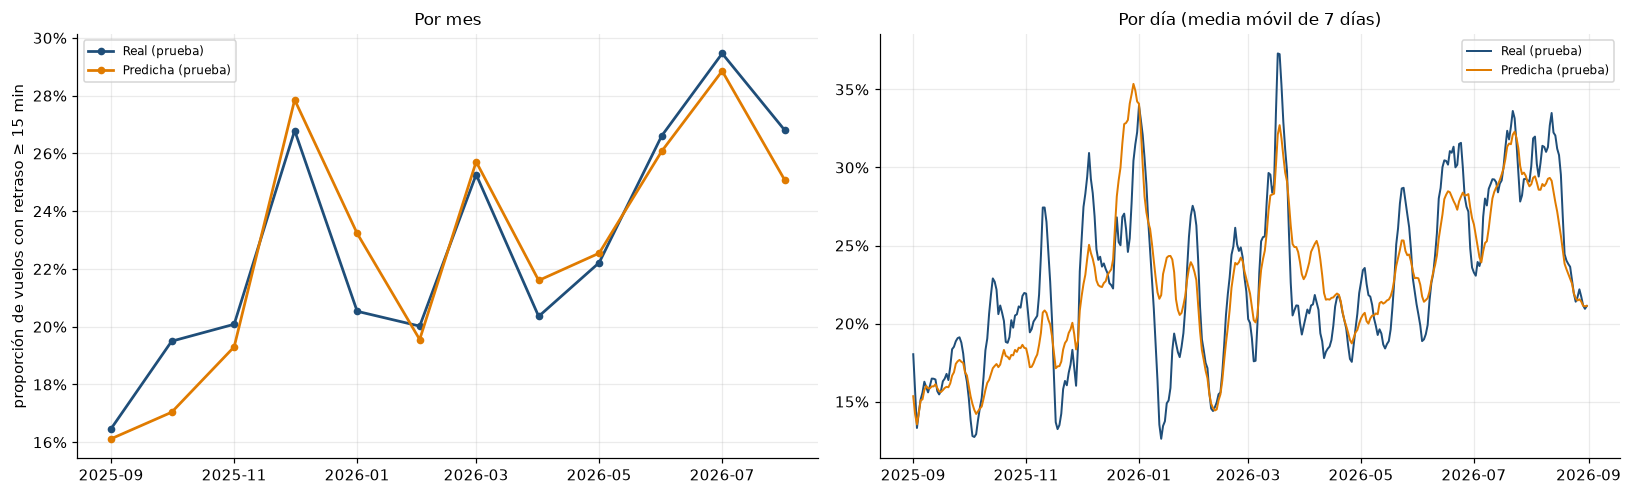

In [3]:
ts = T["timeseries"].copy(); ts["fecha"] = pd.to_datetime(ts.fecha); ts["mes"] = ts.fecha.dt.to_period("M").dt.to_timestamp()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
styles = {c: dict(ls=["-", "--", ":"][i % 3], marker="o" if i == 0 else "s") for i, c in enumerate(CONJ)}
for c in CONJ:
    d = ts[ts.conjunto == c]
    m = d.groupby("mes").agg(v=("vuelos", "sum"), r=("retrasados", "sum"), p=("prob_suma", "sum"))
    ax[0].plot(m.index, m.r / m.v, color=COL_REAL, ms=4, lw=1.8, label=f"Real ({c})", **styles[c])
    ax[0].plot(m.index, m.p / m.v, color=COL_PRED, ms=4, lw=1.8, label=f"Predicha ({c})", **styles[c])
    dd = d.sort_values("fecha").set_index("fecha")
    roll = dd[["vuelos", "retrasados", "prob_suma"]].rolling("7D").sum()
    ax[1].plot(roll.index, roll.retrasados / roll.vuelos, color=COL_REAL, lw=1.3, ls=styles[c]["ls"], label=f"Real ({c})")
    ax[1].plot(roll.index, roll.prob_suma / roll.vuelos, color=COL_PRED, lw=1.3, ls=styles[c]["ls"], label=f"Predicha ({c})")
ax[0].set(title="Por mes", ylabel="proporción de vuelos con retraso ≥ 15 min"); ax[1].set(title="Por día (media móvil de 7 días)")
for a in ax: a.legend(fontsize=8); a.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
save_fig("01_serie_temporal")

## 3. Calibración y separación entre clases

- **Izquierda – calibración:** cada punto es un 1 % de los vuelos, agrupados por probabilidad predicha. Sobre la diagonal, la frecuencia observada coincide con lo que el modelo decía.
- **Derecha – separación:** distribución de la probabilidad predicha para vuelos que **sí** se retrasaron y los que **no**. Cuanto menos se solapan, mejor discrimina. La línea vertical es el umbral por costo.

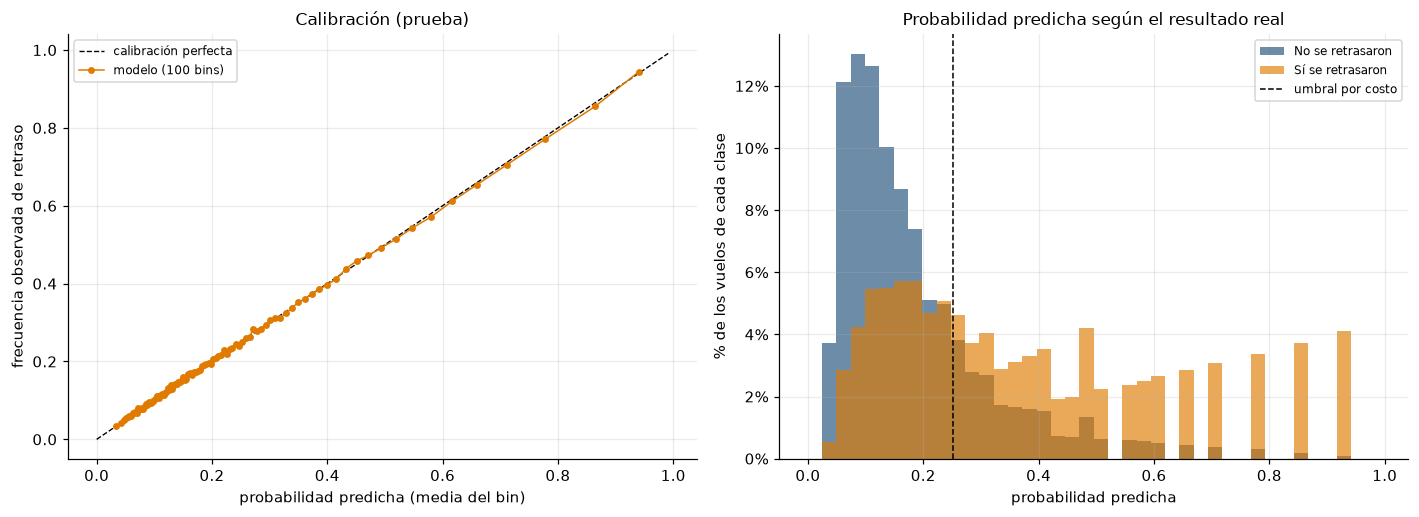

In [4]:
b = T["score_bins"].query("conjunto == @SET").sort_values("bin").copy()
b["tasa"] = b.retrasados / b.vuelos
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
lim = max(b.p_media.max(), b.tasa.max()) * 1.05
ax[0].plot([0, lim], [0, lim], "k--", lw=0.9, label="calibración perfecta")
ax[0].plot(b.p_media, b.tasa, "o-", color=COL_PRED, ms=3.5, lw=1, label="modelo (100 bins)")
ax[0].set(title=f"Calibración ({SET})", xlabel="probabilidad predicha (media del bin)", ylabel="frecuencia observada de retraso")
ax[0].legend(fontsize=8)

edges = np.linspace(0, b.p_max.max(), 41)
pos_w = b.retrasados / b.retrasados.sum(); neg_w = (b.vuelos - b.retrasados) / (b.vuelos - b.retrasados).sum()
ax[1].hist(b.p_media, bins=edges, weights=neg_w, alpha=0.65, color=COL_REAL, label="No se retrasaron")
ax[1].hist(b.p_media, bins=edges, weights=pos_w, alpha=0.65, color=COL_PRED, label="Sí se retrasaron")
ax[1].axvline(meta["conjuntos"][SET]["umbral"], color="k", ls="--", lw=1, label="umbral por costo")
ax[1].set(title="Probabilidad predicha según el resultado real", xlabel="probabilidad predicha", ylabel="% de los vuelos de cada clase")
ax[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax[1].legend(fontsize=8)
save_fig("02_calibracion_separacion")

## 4. ROC, Precisión–Recall y ganancia acumulada

La **ganancia** responde la pregunta operativa: *si solo puedo vigilar el X % de vuelos con mayor riesgo, ¿qué fracción de los retrasos reales capturo?* La diagonal es vigilar al azar.

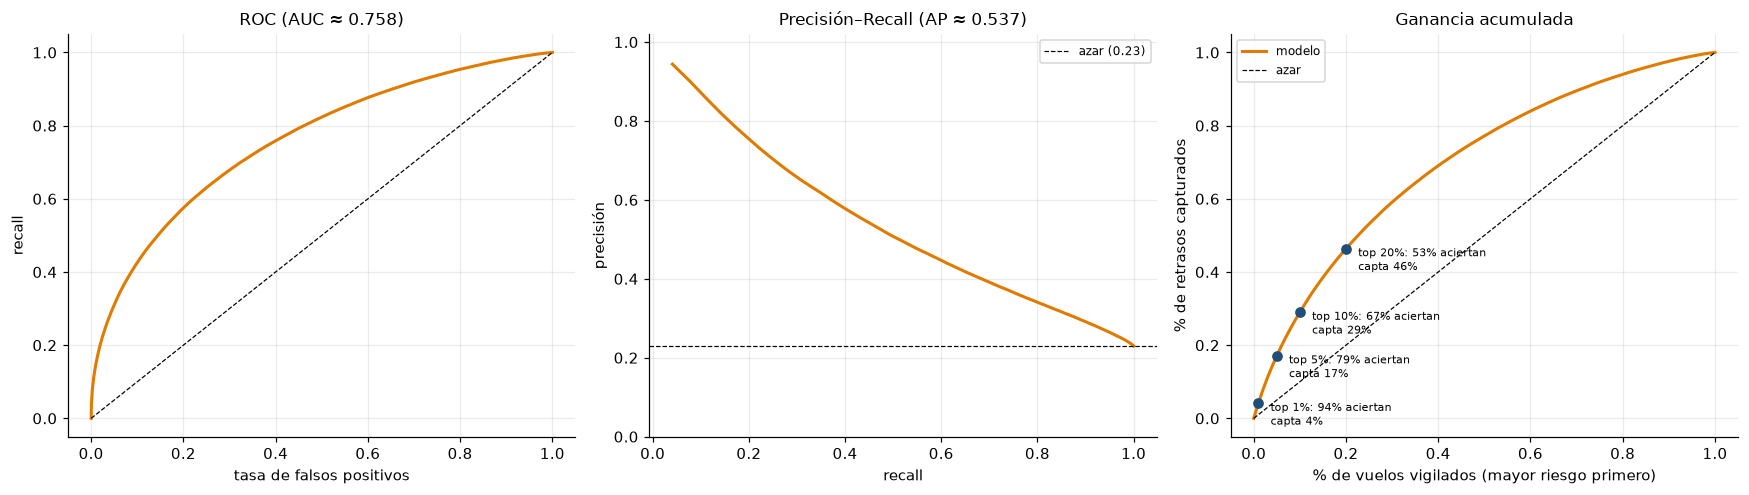

In [5]:
o = b.sort_values("p_media", ascending=False)
N, P = o.vuelos.sum(), o.retrasados.sum()
tp = np.r_[0, o.retrasados.cumsum()]; fp = np.r_[0, (o.vuelos - o.retrasados).cumsum()]
tpr, fpr, prec, share = tp / P, fp / (N - P), np.r_[1, tp[1:] / (tp[1:] + fp[1:])], (tp + fp) / N
auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2); ap = np.sum(np.diff(tpr) * prec[1:])

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].plot(fpr, tpr, color=COL_PRED, lw=2); ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title=f"ROC (AUC ≈ {auc:.3f})", xlabel="tasa de falsos positivos", ylabel="recall")
ax[1].plot(tpr[1:], prec[1:], color=COL_PRED, lw=2); ax[1].axhline(P / N, color="k", ls="--", lw=0.8, label=f"azar ({P / N:.2f})")
ax[1].set(title=f"Precisión–Recall (AP ≈ {ap:.3f})", xlabel="recall", ylabel="precisión", ylim=(0, 1.02)); ax[1].legend(fontsize=8)
ax[2].plot(share, tpr, color=COL_PRED, lw=2, label="modelo"); ax[2].plot([0, 1], [0, 1], "k--", lw=0.8, label="azar")
for k in (0.01, 0.05, 0.10, 0.20):
    i = np.searchsorted(share, k)
    ax[2].plot(share[i], tpr[i], "o", color=COL_REAL); ax[2].annotate(f"top {k:.0%}: {prec[i]:.0%} aciertan\ncapta {tpr[i]:.0%}", (share[i], tpr[i]),
                                                                     textcoords="offset points", xytext=(8, -14), fontsize=7.5)
ax[2].set(title="Ganancia acumulada", xlabel="% de vuelos vigilados (mayor riesgo primero)", ylabel="% de retrasos capturados"); ax[2].legend(fontsize=8)
save_fig("03_roc_pr_ganancia")

## 5. Real vs predicha por subgrupo

Cada gráfica tiene dos paneles: a la izquierda, tasa real y predicha; a la derecha, la **brecha en puntos porcentuales** (predicha − real). Barras a la derecha del cero = el modelo sobreestima el retraso; a la izquierda = lo subestima.

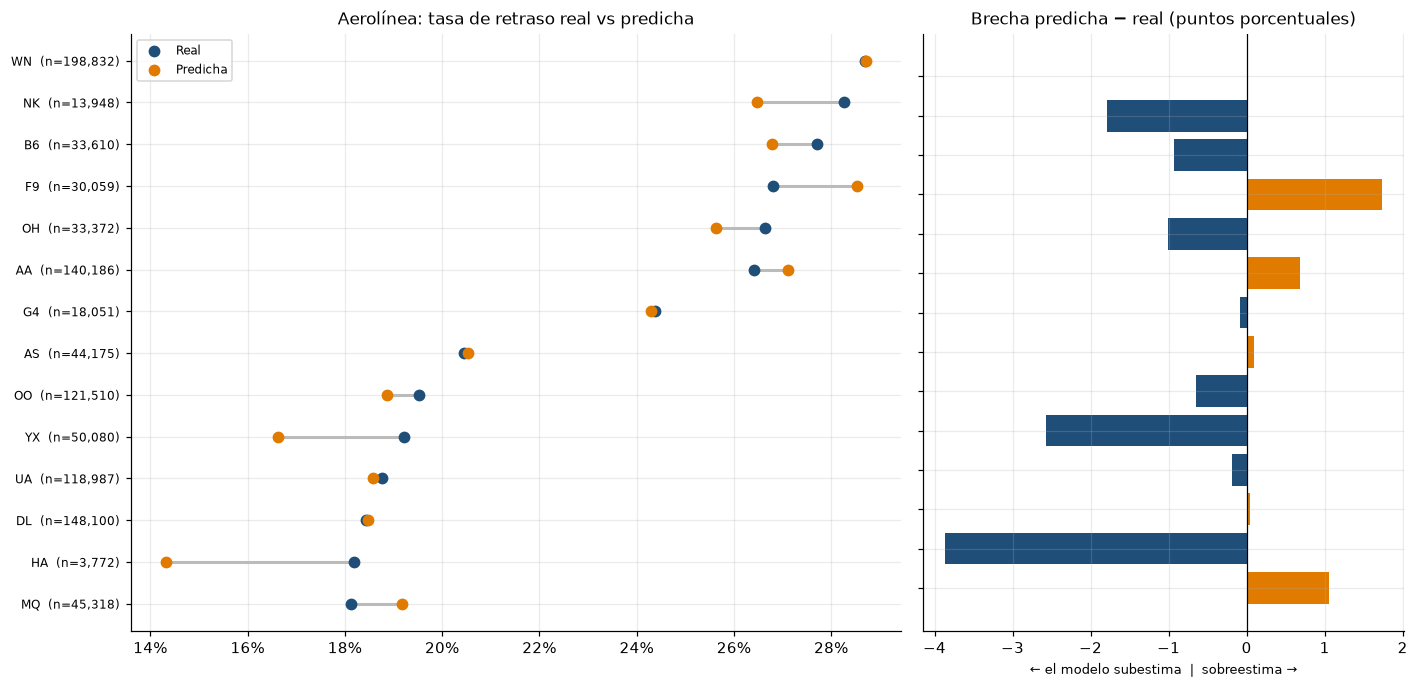

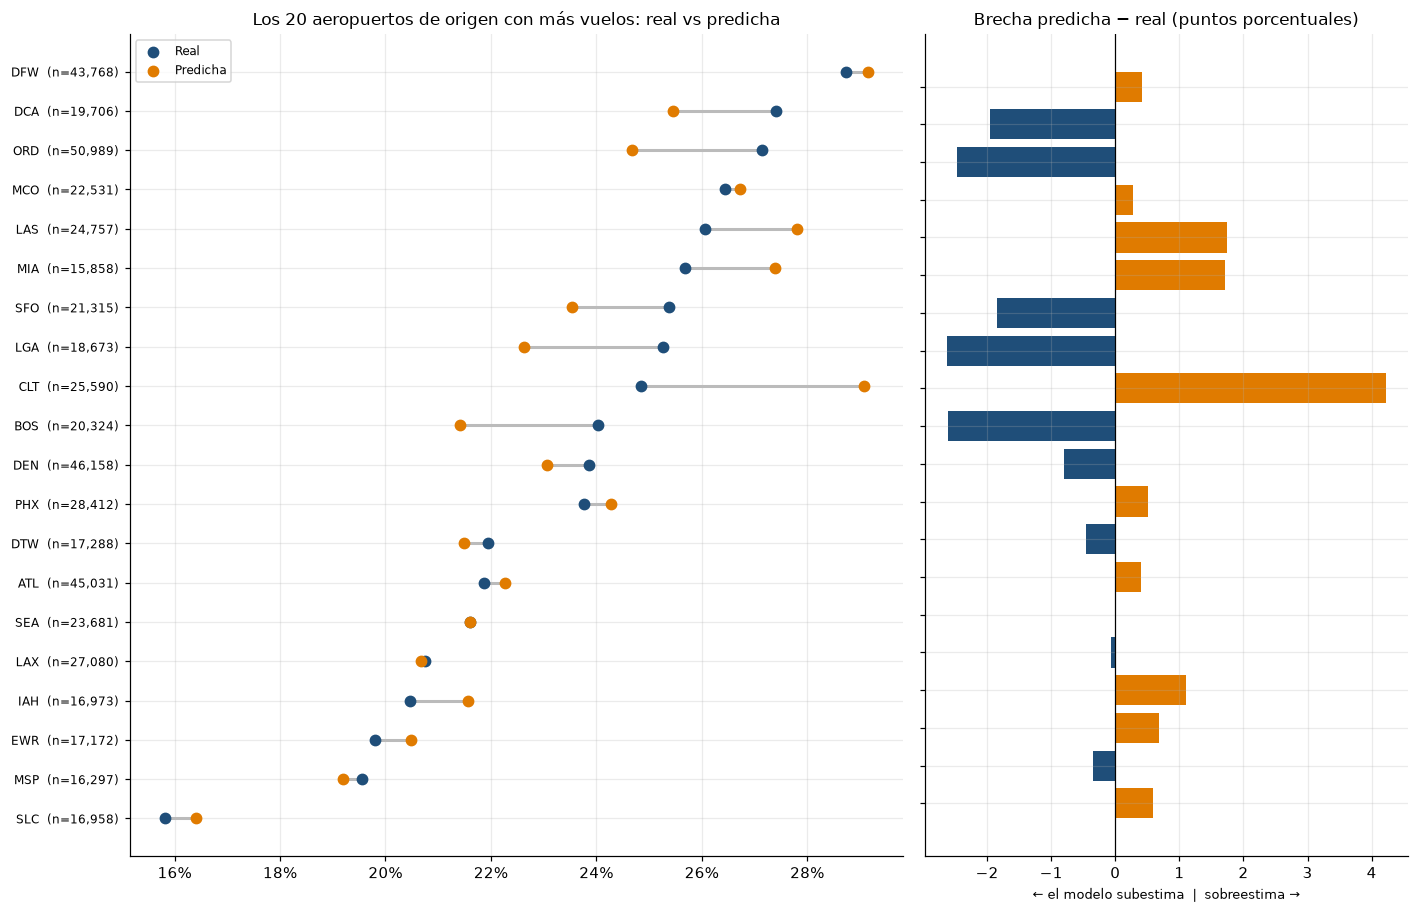

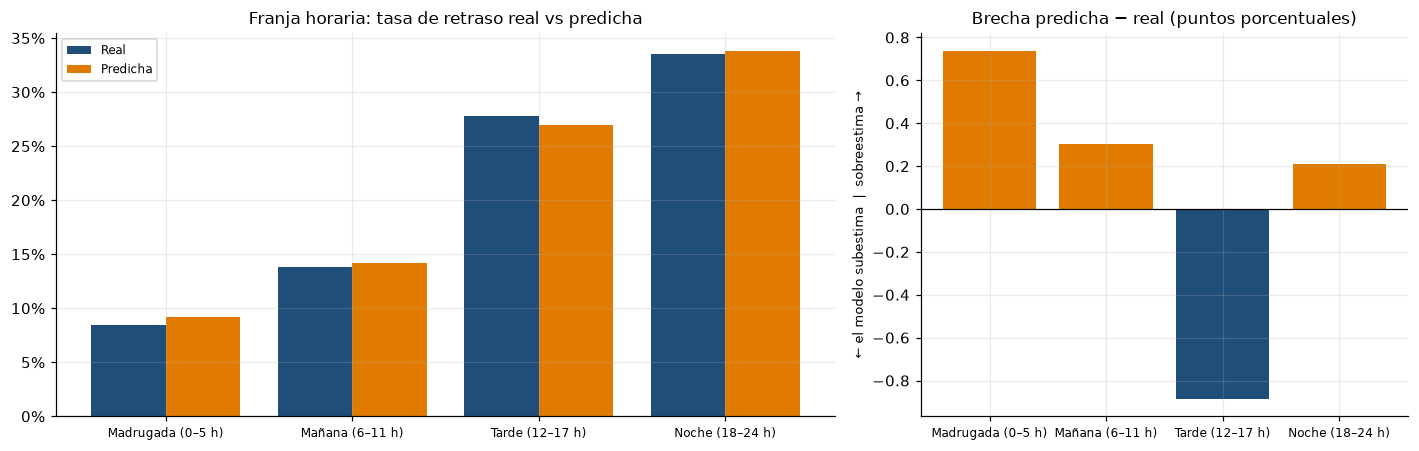

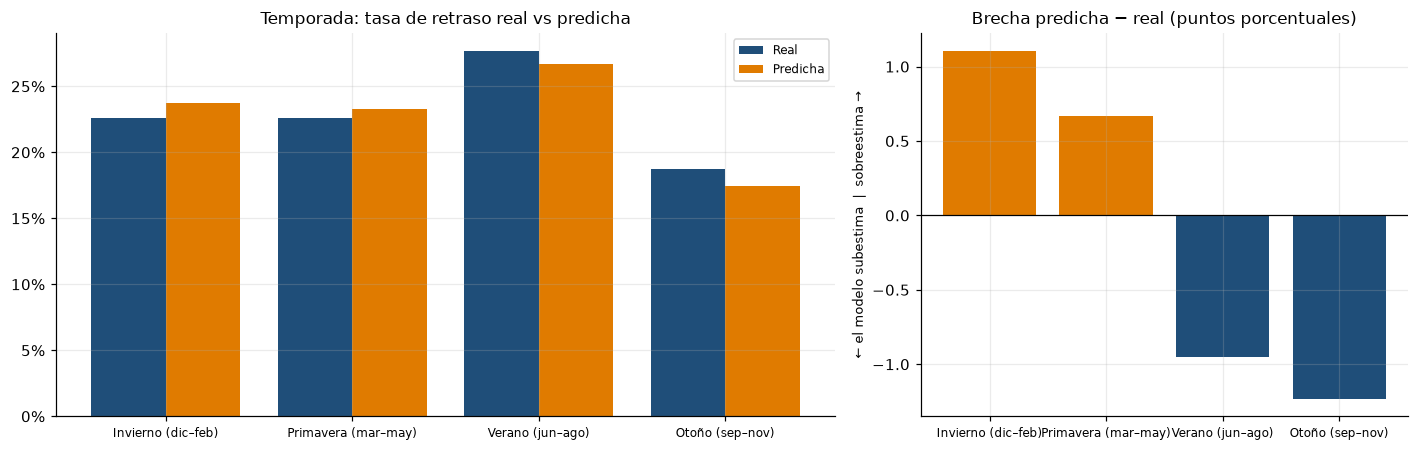

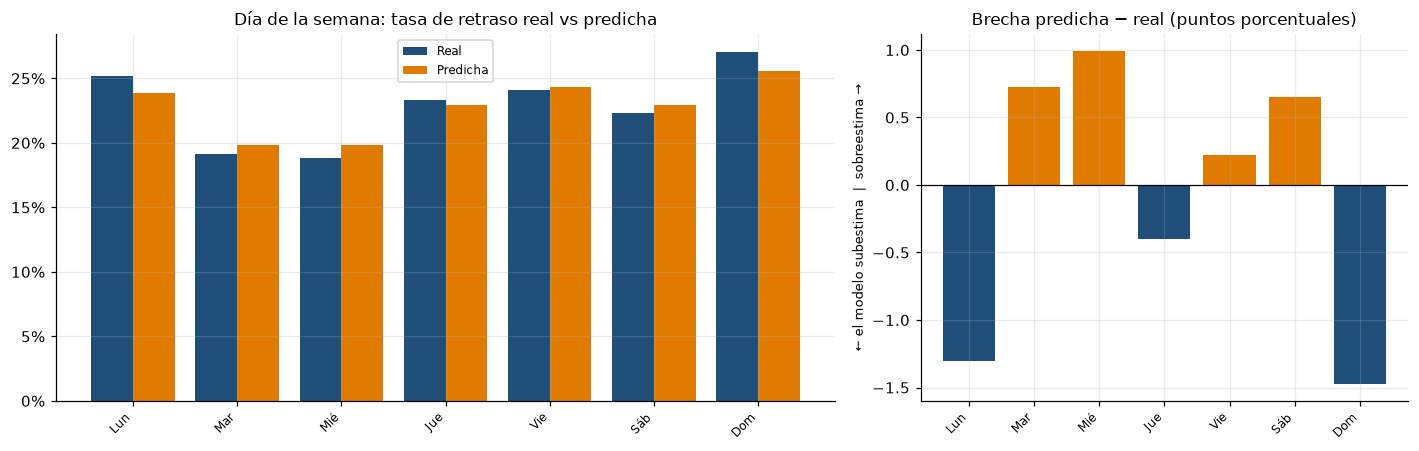

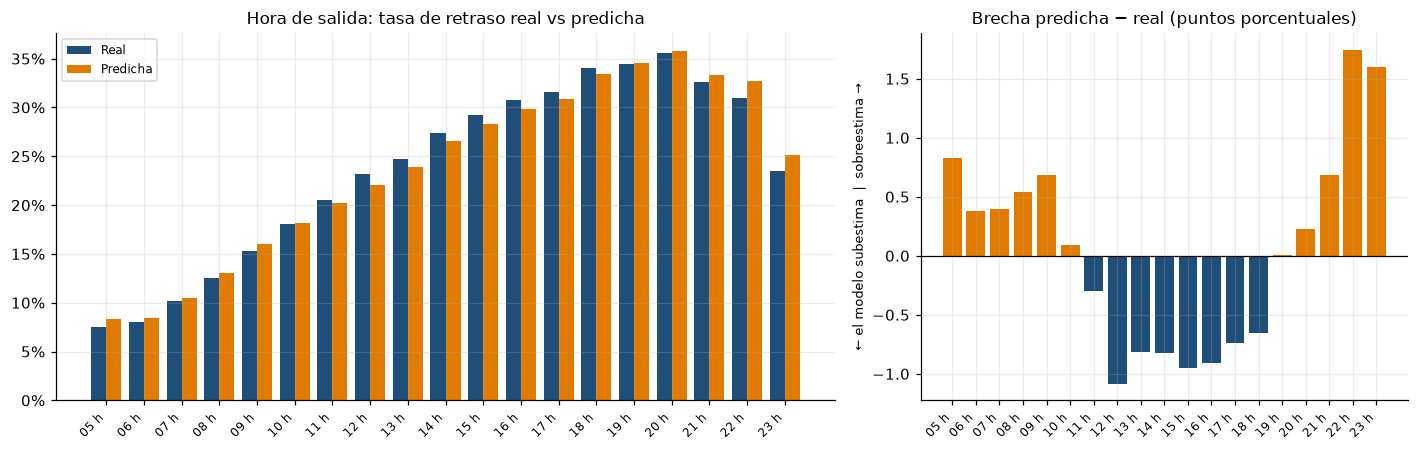

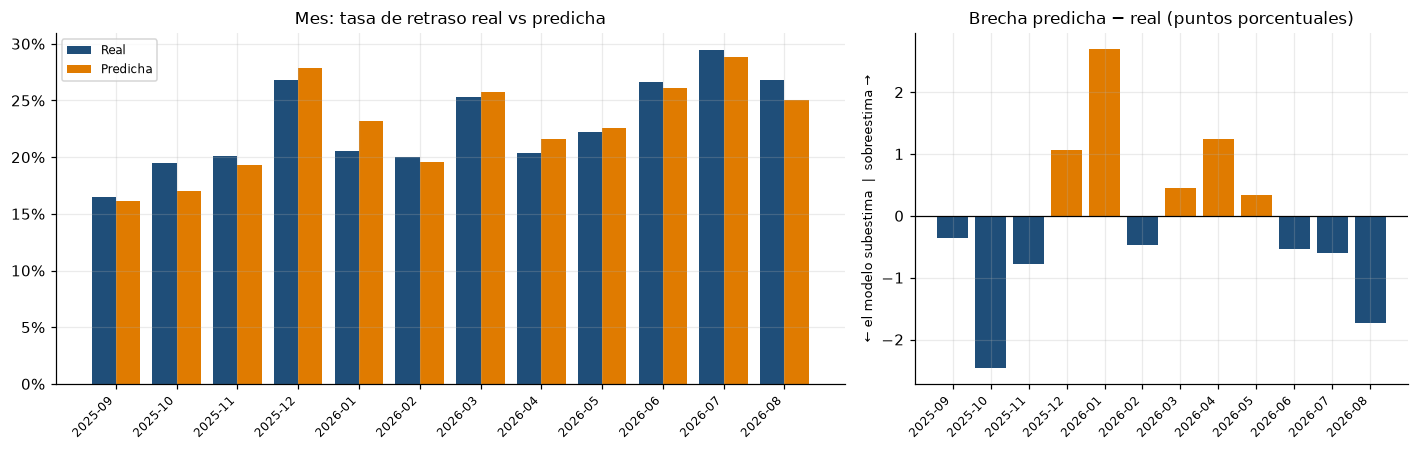

In [6]:
G = T["group_metrics"].query("conjunto == @SET and dimension != 'Global' and vuelos >= @MIN_FLIGHTS").copy()
G["brecha_pp"] = (G.prob_media - G.tasa_real) * 100

def compare(dim, kind, top=None, title=None):
    d = G[G.dimension == dim].sort_values("orden")
    if top: d = d.nsmallest(top, "orden")
    if kind == "dumbbell":
        d = d.sort_values("tasa_real")
    y = np.arange(len(d))
    fig, ax = plt.subplots(1, 2, figsize=(13, max(3.2, 0.34 * len(d) + 1.6)) if kind == "dumbbell" else (13, 4.2),
                           gridspec_kw={"width_ratios": [1.6, 1]})
    if kind == "dumbbell":
        ax[0].hlines(y, d.tasa_real, d.prob_media, color="#bbbbbb", lw=2)
        ax[0].scatter(d.tasa_real, y, color=COL_REAL, s=45, zorder=3, label="Real")
        ax[0].scatter(d.prob_media, y, color=COL_PRED, s=45, zorder=3, label="Predicha")
        ax[0].set_yticks(y, [f"{g}  (n={n:,})" for g, n in zip(d.grupo, d.vuelos)], fontsize=8)
        ax[1].barh(y, d.brecha_pp, color=np.where(d.brecha_pp > 0, COL_PRED, COL_REAL)); ax[1].set_yticks(y, [""] * len(d))
    else:
        x = np.arange(len(d)); w = 0.4
        ax[0].bar(x - w / 2, d.tasa_real, w, color=COL_REAL, label="Real"); ax[0].bar(x + w / 2, d.prob_media, w, color=COL_PRED, label="Predicha")
        ax[0].set_xticks(x, d.grupo, rotation=45 if len(d) > 6 else 0, ha="right" if len(d) > 6 else "center", fontsize=8)
        ax[1].bar(x, d.brecha_pp, color=np.where(d.brecha_pp > 0, COL_PRED, COL_REAL)); ax[1].set_xticks(x, d.grupo, rotation=45 if len(d) > 6 else 0,
                                                                                                    ha="right" if len(d) > 6 else "center", fontsize=8)
    ax[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}") if kind == "dumbbell" else ax[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax[0].set_title(title or f"{dim}: tasa de retraso real vs predicha"); ax[0].legend(fontsize=8)
    ax[1].axvline(0, color="k", lw=0.8) if kind == "dumbbell" else ax[1].axhline(0, color="k", lw=0.8)
    ax[1].set_title("Brecha predicha − real (puntos porcentuales)")
    (ax[1].set_xlabel if kind == "dumbbell" else ax[1].set_ylabel)("← el modelo subestima  |  sobreestima →", fontsize=8.5)
    save_fig(f"04_{dim.lower().replace(' ', '_').replace('é', 'e').replace('í', 'i').replace('ó', 'o')}")

compare("Aerolínea", "dumbbell")
compare("Aeropuerto de origen", "dumbbell", top=TOP_AIRPORTS, title=f"Los {TOP_AIRPORTS} aeropuertos de origen con más vuelos: real vs predicha")
for dim in ["Franja horaria", "Temporada", "Día de la semana", "Hora de salida", "Mes"]:
    compare(dim, "bars")

## 6. Mapa de calor: hora de salida × día de la semana

Muestra **dónde** está la brecha. Celdas con pocos vuelos se dejan en blanco.

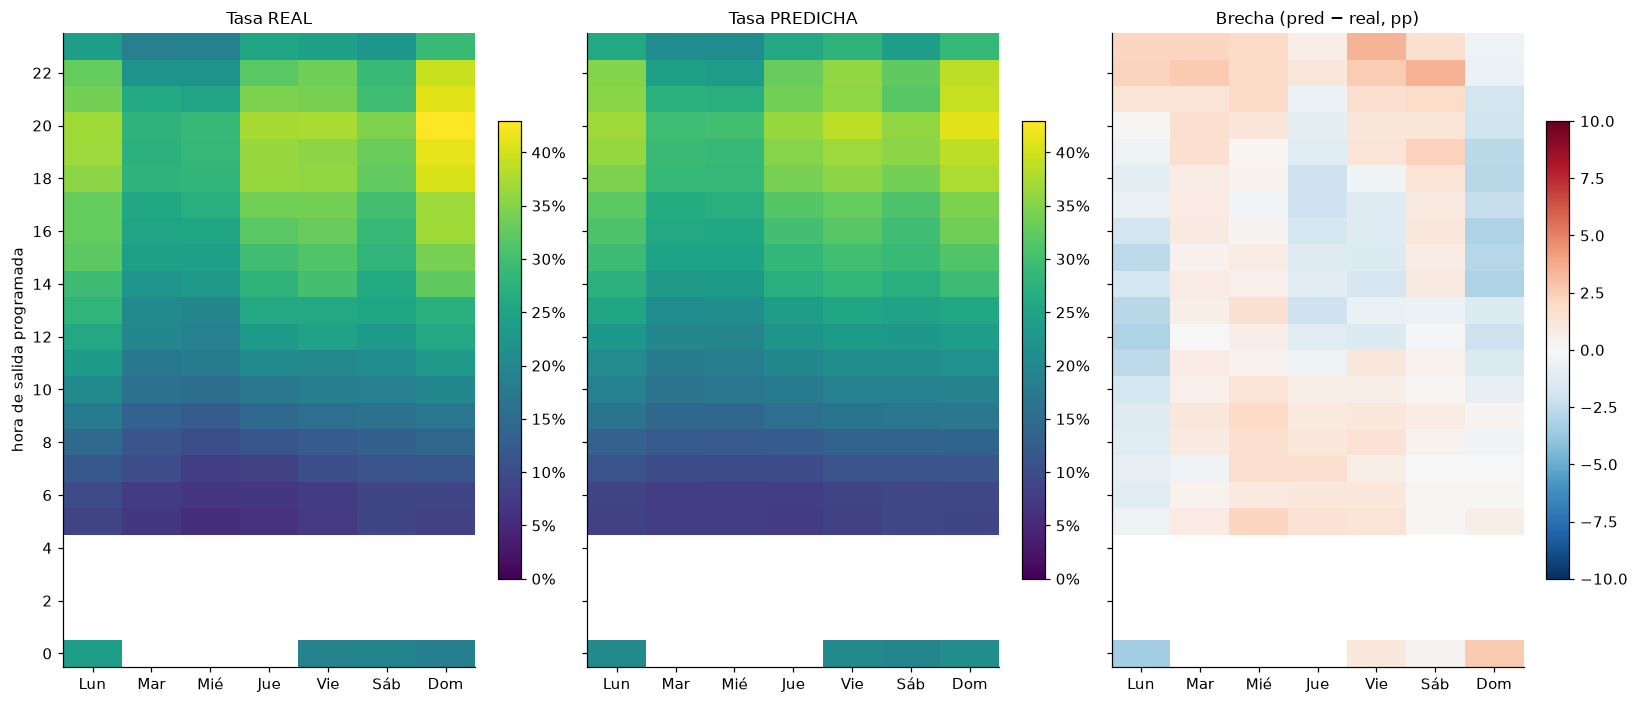

In [7]:
h = T["heat_hora_dia"].query("conjunto == @SET").copy()
h["real"] = h.retrasados / h.vuelos; h["pred"] = h.prob_suma / h.vuelos; h["dif"] = (h.pred - h.real) * 100
mask = h.vuelos < 200
for c in ("real", "pred", "dif"):
    h.loc[mask, c] = np.nan
piv = {c: h.pivot(index="hora", columns="dia_semana", values=c) for c in ("real", "pred", "dif")}
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
vmax = np.nanmax([piv["real"].values, piv["pred"].values])
fig, ax = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
for a, (c, ttl, cmap, lim) in zip(ax, [("real", "Tasa REAL", "viridis", (0, vmax)), ("pred", "Tasa PREDICHA", "viridis", (0, vmax)),
                                       ("dif", "Brecha (pred − real, pp)", "RdBu_r", (-10, 10))]):
    im = a.imshow(piv[c].values, aspect="auto", cmap=cmap, vmin=lim[0], vmax=lim[1], origin="lower")
    a.set_xticks(range(len(dias)), [dias[int(i) - 1] for i in piv[c].columns]); a.set_title(ttl); a.grid(False)
    plt.colorbar(im, ax=a, fraction=0.05, format=(lambda v, _: f"{v:.0%}") if c != "dif" else None)
ax[0].set_yticks(range(len(piv["real"].index))[::2], piv["real"].index[::2]); ax[0].set_ylabel("hora de salida programada")
save_fig("05_mapa_calor_hora_dia")

## 7. Matriz de confusión al umbral por costo

Global y por franja horaria. Cada fila suma 100 %: la fila "Real retraso" muestra qué fracción de los retrasos se detectó (recall) y la fila "Real puntual", cuántos vuelos puntuales se marcaron en falso.

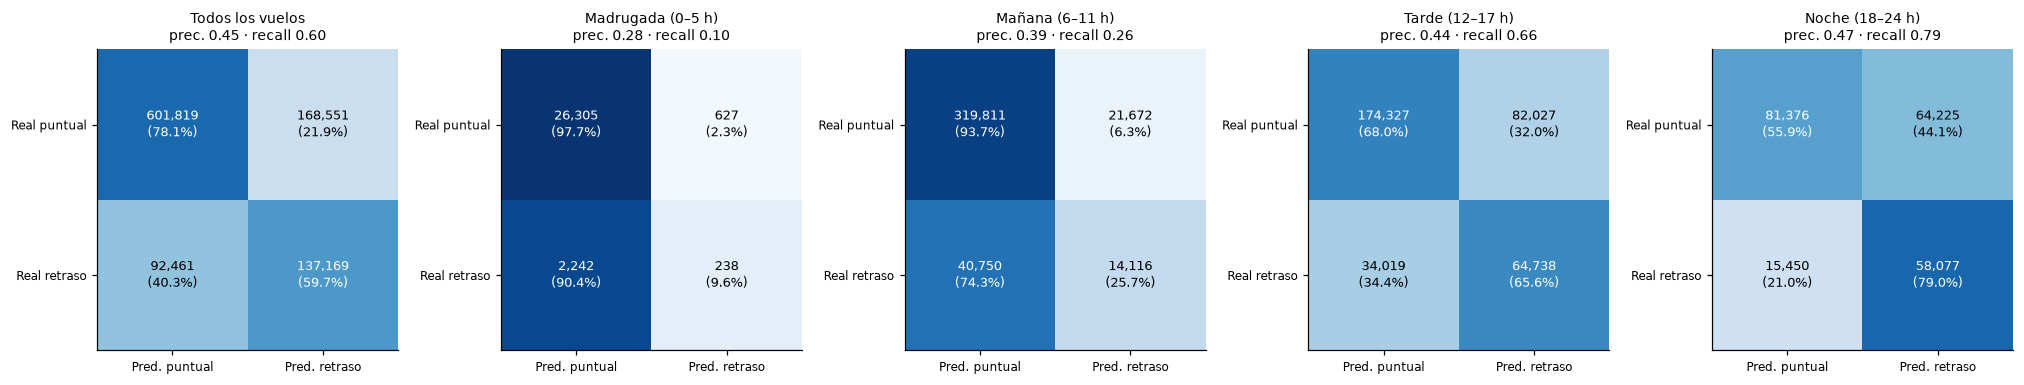

In [8]:
cm_rows = pd.concat([T["group_metrics"].query("conjunto == @SET and dimension == 'Global'"),
                     T["group_metrics"].query("conjunto == @SET and dimension == 'Franja horaria'").sort_values("orden")])
fig, axes = plt.subplots(1, len(cm_rows), figsize=(3.7 * len(cm_rows), 3.9))
for a, (_, r) in zip(np.atleast_1d(axes), cm_rows.iterrows()):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=float); pct = cm / cm.sum(axis=1, keepdims=True)
    a.imshow(pct, cmap="Blues", vmin=0, vmax=1); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{int(cm[i, j]):,}\n({pct[i, j]:.1%})", ha="center", va="center", fontsize=8.5, color="white" if pct[i, j] > 0.5 else "black")
    a.set_xticks([0, 1], ["Pred. puntual", "Pred. retraso"], fontsize=8); a.set_yticks([0, 1], ["Real puntual", "Real retraso"], fontsize=8)
    a.set_title(f"{r.grupo}\nprec. {r.precision:.2f} · recall {r.recall:.2f}", fontsize=9)
save_fig("06_matrices_confusion")

## 8. Sensibilidad al costo del error

La propuesta fija un costo (falsa alarma : retraso no detectado = 1 : 3) que es un **supuesto**. Aquí se ve cómo cambia la decisión si la razón real fuera otra: el umbral óptimo, qué porcentaje de vuelos se marcaría y qué precisión y recall resultarían. El costo está en unidades relativas (una falsa alarma = 1), **no es dinero**.

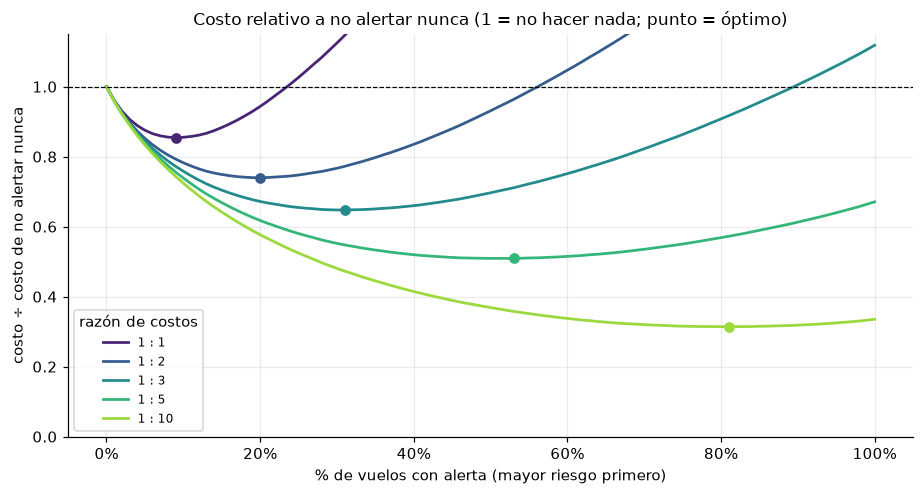

,umbral óptimo ≈,% de vuelos con alerta,precisión,recall,costo por 1000 vuelos (u. relativas),costo vs no alertar nunca
razón (falsa alarma : retraso perdido),,,,,,
1 : 1,0.5056,0.0900,0.6855,0.2687,196.2340,0.8546
1 : 2,0.3333,0.2000,0.5325,0.4638,339.7810,0.7398
1 : 3,0.2496,0.3100,0.4458,0.6018,446.1060,0.6476
1 : 5,0.1573,0.5300,0.3439,0.7937,584.6200,0.5092
1 : 10,0.0881,0.8100,0.2677,0.9442,721.3790,0.3141


In [9]:
RATIOS = [1, 2, 3, 5, 10]
pe = b.sort_values("p_media", ascending=False)
Np, Pp = pe.vuelos.sum(), pe.retrasados.sum()
tp_k = np.r_[0, pe.retrasados.cumsum().values]; fp_k = np.r_[0, (pe.vuelos - pe.retrasados).cumsum().values]
fn_k = Pp - tp_k; share_k = (tp_k + fp_k) / Np
thr_k = np.r_[1.0, pe.p_min.values]                     # umbral aproximado si se alertan los k bins de mayor riesgo
rows = []
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for r, col in zip(RATIOS, plt.cm.viridis(np.linspace(0.1, 0.85, len(RATIOS)))):
    cost = (fp_k + r * fn_k) / Np * 1000
    never = r * Pp / Np * 1000                              # costo de no alertar nunca (se pierden todos los retrasos)
    k = int(np.argmin(cost))
    ax.plot(share_k, cost / never, color=col, lw=1.8, label=f"1 : {r}"); ax.plot(share_k[k], cost[k] / never, "o", color=col)
    rows.append({"razón (falsa alarma : retraso perdido)": f"1 : {r}", "umbral óptimo ≈": thr_k[k], "% de vuelos con alerta": share_k[k],
                 "precisión": tp_k[k] / max(tp_k[k] + fp_k[k], 1), "recall": tp_k[k] / Pp,
                 "costo por 1000 vuelos (u. relativas)": cost[k], "costo vs no alertar nunca": cost[k] / never})
ax.axhline(1, color="k", ls="--", lw=0.8)
ax.set(title="Costo relativo a no alertar nunca (1 = no hacer nada; punto = óptimo)", xlabel="% de vuelos con alerta (mayor riesgo primero)", ylabel="costo ÷ costo de no alertar nunca")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylim(0, 1.15); ax.legend(title="razón de costos", fontsize=8)
save_fig("07_sensibilidad_costo")
display(pd.DataFrame(rows).set_index("razón (falsa alarma : retraso perdido)"))

## 9. Mayores brechas entre predicción y realidad

Subgrupos (con al menos `MIN_FLIGHTS` vuelos) donde el promedio predicho más se aleja de la tasa real, y subgrupos donde el modelo ordena peor los vuelos (ROC-AUC más bajo). Un sesgo localizado se corrige con variables o calibración por grupo, no con hiperparámetros.

In [10]:
cols = ["dimension", "grupo", "vuelos", "tasa_real", "prob_media", "brecha_pp", "sesgo", "roc_auc", "pr_auc"]
print("Mayor brecha absoluta (predicha − real):")
display(G.loc[G.brecha_pp.abs().sort_values(ascending=False).index[:10], cols].reset_index(drop=True))
print("Menor capacidad de ordenar (ROC-AUC más bajo):")
display(G.sort_values("roc_auc").head(10)[cols].reset_index(drop=True))

Mayor brecha absoluta (predicha − real):


,dimension,grupo,vuelos,tasa_real,prob_media,brecha_pp,sesgo,roc_auc,pr_auc
0,Aeropuerto de origen,CLT,25590,0.2485,0.2907,4.2244,1.1700,0.7869,0.6209
1,Aerolínea,HA,3772,0.1819,0.1432,-3.8686,0.7873,0.7377,0.4111
2,Aeropuerto de origen,PVD,2157,0.2188,0.1823,-3.6517,0.8331,0.7538,0.4969
3,Aeropuerto de origen,BWI,13270,0.2789,0.3119,3.3039,1.1185,0.7679,0.6027
4,Aeropuerto de origen,SAN,14351,0.2704,0.2419,-2.8421,0.8949,0.7761,0.5943
5,Mes,2026-01,74555,0.2053,0.2323,2.6958,1.1313,0.7148,0.4696
6,Aeropuerto de origen,LGA,18673,0.2526,0.2263,-2.6301,0.8959,0.7670,0.5990
7,Aeropuerto de origen,BOS,20324,0.2403,0.2141,-2.6177,0.8911,0.7585,0.5620
8,Aerolínea,YX,50080,0.1921,0.1663,-2.5763,0.8659,0.7250,0.4494
9,Aeropuerto de origen,ORD,50989,0.2714,0.2467,-2.4648,0.9092,0.7658,0.6261


Menor capacidad de ordenar (ROC-AUC más bajo):


,dimension,grupo,vuelos,tasa_real,prob_media,brecha_pp,sesgo,roc_auc,pr_auc
0,Hora de salida,06 h,68658,0.0807,0.0845,0.3800,1.0471,0.6161,0.1435
1,Hora de salida,05 h,27224,0.0748,0.0830,0.8251,1.1104,0.6209,0.1226
2,Hora de salida,07 h,74936,0.1014,0.1053,0.3970,1.0392,0.6447,0.2222
3,Franja horaria,Madrugada (0–5 h),29412,0.0843,0.0917,0.7387,1.0876,0.6534,0.1657
4,Hora de salida,08 h,69975,0.1251,0.1305,0.5380,1.0430,0.6660,0.3105
5,Hora de salida,09 h,57231,0.1533,0.1601,0.6860,1.0448,0.6771,0.3616
6,Hora de salida,10 h,63751,0.1809,0.1818,0.0930,1.0051,0.6847,0.4019
7,Aeropuerto de origen,XNA,2079,0.1953,0.1926,-0.2658,0.9864,0.6872,0.4204
8,Hora de salida,11 h,61798,0.2052,0.2022,-0.2987,0.9854,0.6895,0.4377
9,Franja horaria,Mañana (6–11 h),396349,0.1384,0.1415,0.3033,1.0219,0.6924,0.3476


## Nota sobre los datos posteriores a 2026-08

El conjunto `prueba` ya tiene resultados reales, así que no hace falta nada más para este análisis. Si en la capa oro existe un conjunto `prospectivo` (meses que ningún paso del proyecto vio, ni para entrenar ni para elegir modelo), las secciones 1 y 2 lo muestran junto a la prueba, y cambiando `SET = "prospectivo"` arriba todas las demás gráficas se calculan sobre él. Es la comparación más honesta del modelo.